In [1]:
import sys; sys.path.insert(0, "../src")
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sfftradar.sfft import tone, permute

N, sigma = 256, 5
x = tone(N, 37)
y = permute(x, sigma)

print(np.argmax(np.abs(np.fft.fft(x))))     # where the tone is before
print(np.argmax(np.abs(np.fft.fft(y))))     # where it is after
print((sigma * 37) % N)                     # where it should be

37
185
185


In [3]:
sigma_inv = pow(sigma, -1, N)       # inverse of 5 mod 256
print(sigma_inv, (185 * sigma_inv) % N)

205 37


samples used: 141
flat part (|d| <= 5): 0.9773 1.0001
leak outside (|d| >= 13): 0.0004


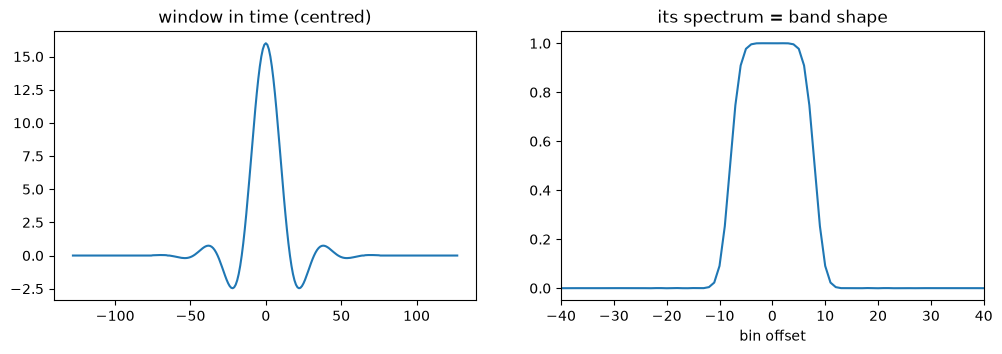

In [4]:
from sfftradar.sfft import flat_window

N, B = 256, 16
w, G = flat_window(N, B)
Gw = np.real(np.fft.fft(w)) / N           # band shape of the truncated window
d = np.fft.fftfreq(N, 1 / N)

print("samples used:", np.count_nonzero(w))
print("flat part (|d| <= 5):", Gw[np.abs(d) <= 5].min().round(4), Gw[np.abs(d) <= 5].max().round(4))
print("leak outside (|d| >= 13):", np.abs(Gw[np.abs(d) >= 13]).max().round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(np.arange(N) - N // 2, np.fft.fftshift(w)); ax[0].set_title("window in time (centred)")
ax[1].plot(np.fft.fftshift(d), np.fft.fftshift(Gw)); ax[1].set_xlim(-40, 40)
ax[1].set_title("its spectrum = band shape"); ax[1].set_xlabel("bin offset")
plt.show()

In [5]:
from sfftradar.sfft import hash_to_bins

N, B = 256, 16
L = N // B
n = np.arange(N)
Gw = np.real(np.fft.fft(w)) / N                  # band shape of the real window

# Test 1: a random mix of 6 tones. The cheap buckets must equal the formula.
rng = np.random.default_rng(1)
freqs = rng.choice(N, 6, replace=False)
amps  = rng.standard_normal(6) + 1j * rng.standard_normal(6)
x = sum(a * tone(N, f) for f, a in zip(freqs, amps))

sigma, tau = 5, 1
u = hash_to_bins(x, sigma, tau, w, B)
Y = np.fft.fft(x[(sigma * (n + tau)) % N])        # full FFT of the permuted signal (check only)
pred = np.array([np.sum(Y * Gw[(n - j * L) % N]) for j in range(B)])
print("max error vs formula:", np.abs(u - pred).max())

# Test 2: one car = 12 DDM copies 16 bins apart
car = sum(tone(N, 3 + 16 * k) for k in range(12))
print("sigma=5:", np.round(np.abs(hash_to_bins(car, 5, 0, w, B)) / N, 2))
print("sigma=1:", np.round(np.abs(hash_to_bins(car, 1, 0, w, B)) / N, 2))

max error vs formula: 5.728578676879116e-14
sigma=5: [1. 1. 0. 1. 1. 1. 1. 0. 1. 1. 1. 1. 0. 0. 1. 1.]
sigma=1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0.]


In [6]:
from sfftradar.sfft import locate

N, B = 256, 16
rng = np.random.default_rng(2)
freqs = rng.choice(N, 5, replace=False)
amps  = rng.standard_normal(5) + 1j * rng.standard_normal(5)
x = sum(a * tone(N, f) for f, a in zip(freqs, amps))
X = np.fft.fft(x)                                       # check only

print("true:", sorted(freqs.tolist()))
found = locate(x, 5, w, B, thresh=0.05 * N)
for f in sorted(found):
    print(f, np.round(found[f], 2), " true X:", np.round(X[f], 2))

car = sum(tone(N, 3 + 16 * k) for k in range(12))
print("car:", sorted(locate(car, 5, w, B, thresh=0.05 * N)))

true: [27, 66, 76, 105, 211]
66 (72.02-202.86j)  true X: (71.99-202.79j)
105 (-141.69+116.43j)  true X: (-141.78+116.47j)
211 (198.15-84.19j)  true X: (198.09-84.18j)
229 (307.15+254.08j)  true X: 0j
car: [3, 19, 35, 51, 67, 83, 99, 115, 131, 147, 163, 179]


In [9]:
from sfftradar.sfft import sparse_fft

# Test 1: the 5-target row (had the 27 + 76 collision)
est = sparse_fft(x, B, w, rng=np.random.default_rng(0))
for f in sorted(est):
    print(f, np.round(est[f], 2), " true X:", np.round(X[f], 2))

# Test 2: two cars at almost the same speed
two = tone(N, 64) + 0.6 * tone(N, 65)
print({f: np.round(v, 1) for f, v in sparse_fft(two, B, w, rng=np.random.default_rng(0)).items()})

# Test 3: how many tones can 16 buckets handle?
r2 = np.random.default_rng(7)
for K in (1, 5, 8, 12, 20):
    ok = 0
    for _ in range(200):
        fr = r2.choice(N, K, replace=False)
        am = r2.standard_normal(K) + 1j * r2.standard_normal(K)
        xx = sum(a * tone(N, f) for f, a in zip(fr, am))
        XX = np.fft.fft(xx)
        Xh = np.zeros(N, complex)
        for f, v in sparse_fft(xx, B, w, rng=r2).items():
            Xh[f] = v
        ok += np.abs(Xh - XX).max() < 1e-3 * np.abs(XX).max()
    print(K, ok / 200)

27 (-83.31-79.5j)  true X: (-83.31-79.5j)
66 (71.99-202.79j)  true X: (71.99-202.79j)
76 (292.91+250.26j)  true X: (292.91+250.26j)
105 (-141.78+116.47j)  true X: (-141.78+116.47j)
211 (198.09-84.18j)  true X: (198.09-84.18j)
{65: np.complex128(153.6-0j), 64: np.complex128(256-0j)}
1 1.0
5 1.0
8 0.975
12 0.56
20 0.005


In [ ]:
from sfftradar.sfft import dense_ops, sparse_ops

print("dense FFT:", dense_ops(N))
rng = np.random.default_rng(3)
for B in (16, 32, 64):
    wB, _ = flat_window(N, B)
    line = []
    for K in (1, 5, 8, 12, 20, 36):
        ok, cost = 0, []
        for _ in range(100):
            fr = rng.choice(N, K, replace=False)
            am = rng.standard_normal(K) + 1j * rng.standard_normal(K)
            xx = sum(a * tone(N, f) for f, a in zip(fr, am))
            XX = np.fft.fft(xx)
            st = {}
            Xh = np.zeros(N, complex)
            for f, v in sparse_fft(xx, B, wB, rng=rng, stats=st).items():
                Xh[f] = v
            ok += np.abs(Xh - XX).max() < 1e-2 * np.abs(XX).max()
            cost.append(sparse_ops(N, B, wB, st["rounds"]))
        line.append(f"K={K}: {ok/100:.2f} / {int(np.median(cost))}")
    print(f"B={B}:", "  ".join(line))


dense FFT: 1024
B=16: K=1: 1.00 / 378  K=5: 1.00 / 1512  K=8: 1.00 / 2646  K=12: 0.93 / 4536  K=20: 0.09 / 4536  K=36: 0.00 / 4536
B=32: K=1: 1.00 / 546  K=5: 1.00 / 1638  K=8: 1.00 / 2730  K=12: 1.00 / 6552  K=20: 0.98 / 6552  K=36: 0.00 / 6552
B=64: K=1: 1.00 / 862  K=5: 1.00 / 2586  K=8: 1.00 / 3448  K=12: 1.00 / 10344  K=20: 1.00 / 10344  K=36: 0.91 / 10344
